# Finding PAL floats and processing several

Which floats carry a passive acoustic listener (PAL), where and when did
they measure, and what wind did they see?  This notebook:

1. finds every float on the Argo GDAC with PAL data;
2. maps where they measured;
3. selects floats by region and period;
4. processes each of them;
5. compares them.

In [1]:
import warnings

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import pandas as pd

import argopal

warnings.simplefilter("ignore")

## 1. Find the floats

No GDAC index says which floats have acoustic data, so
`find_pal_floats` checks every float folder in the GDAC's `aux/`
directory for the PAL spectrum variable.  This takes a couple of minutes
the first time; the list is then saved in `argopal_data/pal_floats.csv`
and reused for a week (`refresh=True` scans again).

Where and when each float measured comes from the GDAC's index of BGC
profiles.

In [2]:
floats = argopal.find_pal_floats()
floats

PAL floats from argopal_data/pal_floats.csv (scanned 2026-11-22).


,wmo,dac,n_profiles,first_date,last_date,first_latitude,first_longitude,last_latitude,last_longitude
0,2904023,coriolis,106,2025-07-13 16:56:53,2026-11-17 12:48:58,39.526,12.926,38.887,15.849
1,2904024,coriolis,106,2025-07-12 17:03:47,2026-11-18 14:24:11,40.667,10.818,40.674,11.268
2,7902280,coriolis,77,2026-01-13 10:02:08,2026-11-14 23:26:17,43.754,9.090,41.231,5.227
3,7902388,coriolis,30,2026-01-29 07:39:07,2026-11-13 09:00:37,8.060,-89.961,8.294,-87.917


## 2. Where they measured

Every profile of these floats, from the same index.  `argopal.map_axes`
makes a map in ArgoPAL's style (global here, since the floats are far
apart; regional when they are close together):

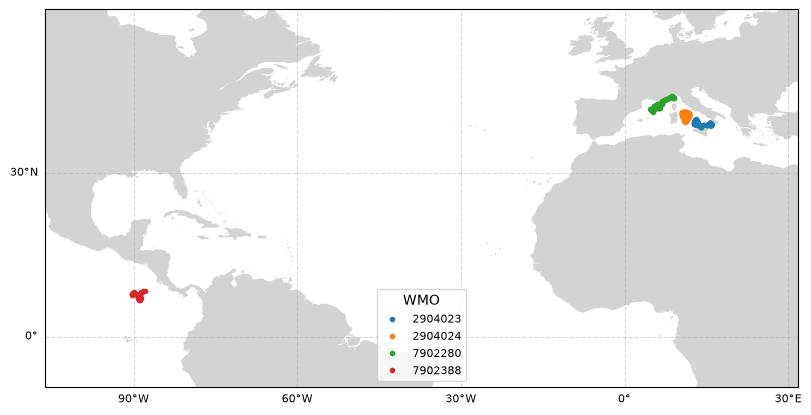

In [3]:
index = argopal.read_profile_index(floats["wmo"])

fig, ax = argopal.map_axes(index["longitude"], index["latitude"])
for wmo, g in index.groupby("wmo"):
    ax.plot(g["longitude"], g["latitude"], "o", ms=3, label=wmo,
            transform=ccrs.PlateCarree())
_ = ax.legend(title="WMO", fontsize=8, loc="lower center")

## 3. Select by region and period

For example the floats with profiles in the western Mediterranean in
2026.  Any condition on the index works (position, date, cycle, ...).

In [4]:
region = index["longitude"].between(-6, 17) & index["latitude"].between(35, 45)
period = index["datetime"].between("2026-01-01", "2026-12-31")
selected = sorted(int(w) for w in index.loc[region & period, "wmo"].unique())
selected

[2904023, 2904024, 7902280]

## 4. Process each float

`process_float` on each, in a loop that carries on if one float fails
(e.g. a file being updated on the GDAC), with the WMO number added to
each table.

These floats are recent, so most of their data are not in delayed mode
yet: `mode="raw"` uses the real-time values (see the
[tutorial on the full pipeline](argopal_tutorial.ipynb) for the modes).

In [5]:
results, failed = {}, {}
for wmo in selected:
    try:
        results[wmo] = argopal.process_float(wmo, mode="raw", verbose=False)
    except Exception as e:
        failed[wmo] = f"{type(e).__name__}: {e}"
print("processed:", list(results), "failed:", failed)

processed: [2904023, 2904024, 7902280] failed: {}


All the park tables in one, with a `wmo` column:

In [6]:
park = pd.concat(
    [r["park"].assign(wmo=wmo) for wmo, r in results.items()],
    ignore_index=True,
)
park.groupby("wmo").agg(
    measurements=("datetime", "size"),
    first=("datetime", "min"),
    last=("datetime", "max"),
    park_depth_m=("depth", "median"),
).round(0)

,measurements,first,last,park_depth_m
wmo,,,,
2904023,42436,2025-07-13 01:37:48.637331456,2026-11-17 07:26:23.429633536,983.0
2904024,41079,2025-07-12 01:25:26.999998976,2026-11-17 23:24:59.378622464,990.0
7902280,72136,2026-01-12 04:48:59.446877696,2026-11-14 09:19:41.102288384,982.0


The floats do not all send the same spectra: some send all 23 bands,
others mostly the 9-band subset (`pal_raw` keeps every band):

In [7]:
pd.DataFrame(
    {wmo: r["pal_raw"].attrs["band_layout_counts"] for wmo, r in results.items()}
).T

,23,9,other
2904023,42432,4,0
2904024,41074,5,0
7902280,306,71830,0


## 5. Compare the floats

Daily median wind speed from the published Nystuen et al. (2015) model.
Without a reference buoy, these winds are not calibrated: the published
models are biased on floats (see the
[full-pipeline tutorial](argopal_tutorial.ipynb), section 7), so this
compares the floats with each other rather than giving absolute winds.

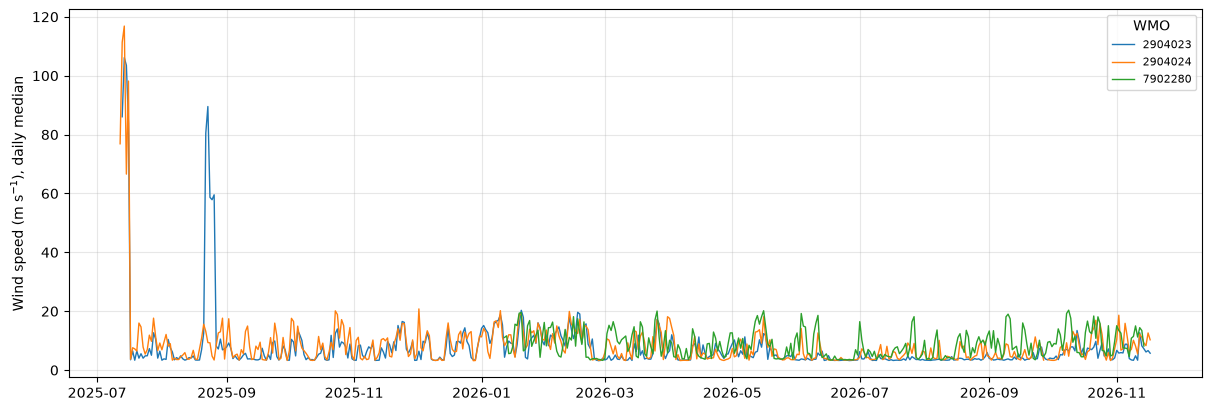

In [8]:
def daily_median(park):
    return (
        park.set_index("datetime")
        .groupby("wmo")["U_nystuen2015"]
        .resample("1D")
        .median()
        .unstack(0)
    )


def plot_daily(daily, ylim=None):
    fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
    for wmo in daily:
        ax.plot(daily.index, daily[wmo], lw=1, label=wmo)
    ax.set_ylabel("Wind speed (m s$^{-1}$), daily median")
    ax.set_ylim(ylim)
    ax.grid(alpha=0.3)
    ax.legend(title="WMO", fontsize=8)


plot_daily(daily_median(park))

Some days reach 80–120 m s⁻¹, which is not wind.  They come from a few
cycles where the float recorded loud, **flat** spectra: wind noise falls
with frequency, these do not.  Float 2904023, cycle 17 against the cycle
before:

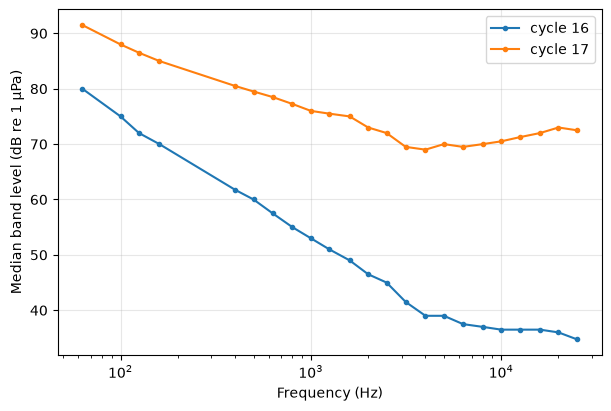

In [9]:
raw = results[2904023]["pal_raw"]
bands = [c for c in raw if c.startswith("f_") and raw[c].notna().mean() > 0.5]
freqs = [int(c[2:-2]) for c in bands]

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
for cycle in (16, 17):
    ax.plot(freqs, raw.loc[raw["cycle"] == cycle, bands].median(), ".-",
            label=f"cycle {cycle}")
ax.set_xscale("log")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Median band level (dB re 1 µPa)")
ax.grid(alpha=0.3)
_ = ax.legend()

ArgoPAL does not flag such spectra yet (despiking removes short events,
not a whole cycle).  For the comparison below, measurements above
30 m s⁻¹ are left out:

left out: 447 of 155651 measurements


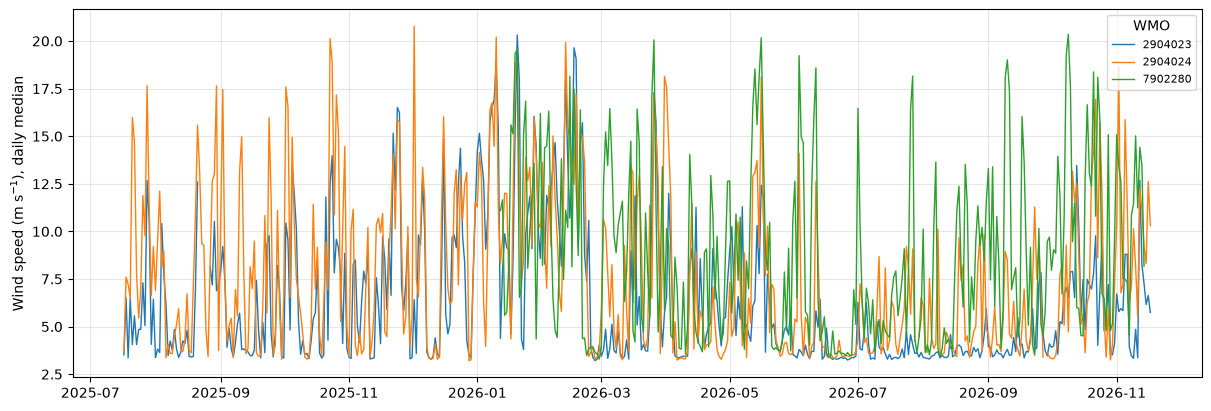

In [10]:
clean = park[park["U_nystuen2015"] <= 30]
print(f"left out: {len(park) - len(clean)} of {len(park)} measurements")
plot_daily(daily_median(clean))

Wind along each track (daily medians at the float's daily position):

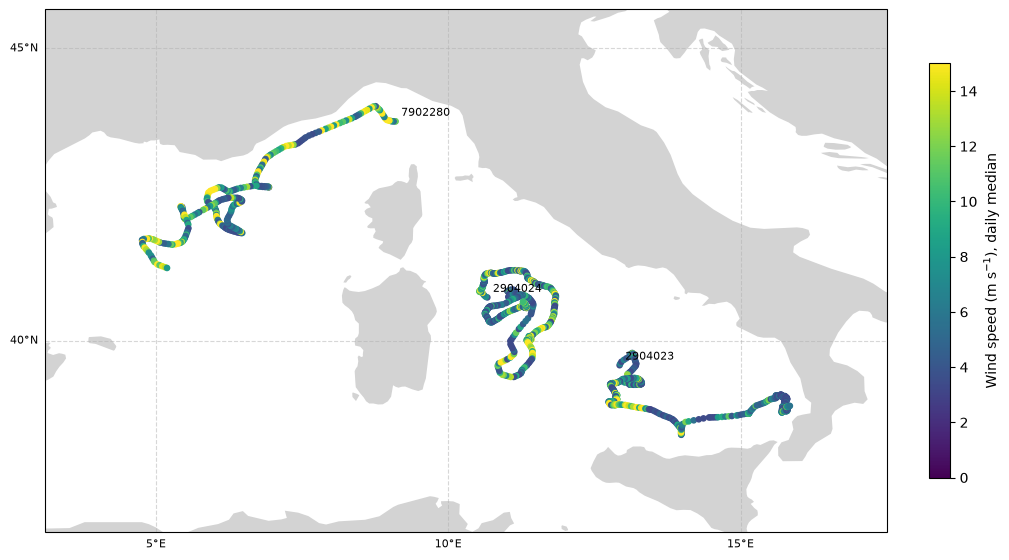

In [11]:
track = (
    clean.set_index("datetime")
    .groupby("wmo")[["longitude", "latitude", "U_nystuen2015"]]
    .resample("1D")
    .median()
    .dropna()
    .reset_index()
)

pc = ccrs.PlateCarree()
fig, ax = argopal.map_axes(track["longitude"], track["latitude"],
                           figsize=(10, 6))
sc = ax.scatter(
    track["longitude"], track["latitude"], c=track["U_nystuen2015"],
    cmap="viridis", s=14, vmin=0, vmax=15, transform=pc, zorder=3,
)
for wmo, g in track.groupby("wmo"):
    ax.annotate(wmo, (g["longitude"].iloc[0], g["latitude"].iloc[0]),
                xycoords=pc._as_mpl_transform(ax), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
fig.colorbar(sc, ax=ax, shrink=0.7,
             label="Wind speed (m s$^{-1}$), daily median")

Monthly statistics per float:

In [12]:
(
    clean.assign(month=clean["datetime"].dt.to_period("M"))
    .groupby(["wmo", "month"])["U_nystuen2015"]
    .median()
    .unstack(0)
    .round(1)
    .tail(6)
)

wmo,2904023,2904024,7902280
month,,,
2026-06,3.4,3.7,4.4
2026-07,3.5,4.8,5.8
2026-08,3.6,4.3,6.3
2026-09,3.9,4.5,7.9
2026-10,5.9,7.0,11.5
2026-11,6.1,10.7,11.6


## 6. Save

One NetCDF file per float, or the combined park table as one CSV file:

In [13]:
for wmo, r in results.items():
    argopal.export(r, f"output/wmo{wmo}.nc", format="netcdf")
argopal.export(park, "output/park_all_floats.csv")

['output/park_all_floats.csv']

With reference winds for the region (a table with `reference_name`,
`datetime`, `latitude`, `longitude`, `wind_speed`), the same loop
calibrates every float: `argopal.process_float(wmo, reference=...)`.